In [1]:
import pandas as pd

archivos = ["BD 2024.xlsx", "BD 2025.xlsx"]

for a in archivos:
    hojas = pd.read_excel(a, sheet_name=None)
    for nombre, df in hojas.items():
        print(a, nombre, df.shape)

BD 2024.xlsx CE (8784, 16)
BD 2024.xlsx NE (8784, 16)
BD 2024.xlsx NE2 (8782, 16)
BD 2024.xlsx NE3 (8782, 16)
BD 2024.xlsx NO (8783, 16)
BD 2024.xlsx NO2 (8782, 16)
BD 2024.xlsx NO3 (8784, 16)
BD 2024.xlsx NTE (8782, 16)
BD 2024.xlsx NTE2 (8782, 16)
BD 2024.xlsx SE (8784, 16)
BD 2024.xlsx SE2 (8782, 16)
BD 2024.xlsx SE3 (8782, 16)
BD 2024.xlsx SO (8784, 16)
BD 2024.xlsx SO2 (8782, 16)
BD 2024.xlsx SUR (8782, 16)
BD 2025.xlsx CE (8759, 16)
BD 2025.xlsx NE (8758, 16)
BD 2025.xlsx NE2 (8758, 16)
BD 2025.xlsx NE3 (8759, 16)
BD 2025.xlsx NO (8759, 16)
BD 2025.xlsx NO2 (8758, 16)
BD 2025.xlsx NO3 (8759, 16)
BD 2025.xlsx NTE (8759, 16)
BD 2025.xlsx NTE2 (8758, 16)
BD 2025.xlsx SE (8759, 16)
BD 2025.xlsx SE2 (8759, 16)
BD 2025.xlsx SE3 (8758, 16)
BD 2025.xlsx SO (8758, 16)
BD 2025.xlsx SO2 (8758, 16)
BD 2025.xlsx SUR (8759, 16)


In [2]:
import pandas as pd

archivos = ["BD 2024.xlsx", "BD 2025.xlsx"]

partes = []
for a in archivos:
    hojas = pd.read_excel(a, sheet_name=None)
    for estacion, d in hojas.items():
        d["estacion"] = estacion
        partes.append(d)

# Revisa que todas las hojas tengan las mismas columnas
columnas = {tuple(p.columns) for p in partes}
print(len(columnas), "estructura(s) distinta(s)")

df = pd.concat(partes, ignore_index=True)
print(df.shape)
df.to_csv("base_unida.csv", index=False)

2 estructura(s) distinta(s)
(263119, 18)


In [3]:
from collections import Counter

conteo = Counter(tuple(p.columns) for p in partes)
estructuras = list(conteo.keys())

for i, cols in enumerate(estructuras):
    print(f"Estructura {i+1}: {conteo[cols]} hojas")

print("Solo en la 1:", set(estructuras[0]) - set(estructuras[1]))
print("Solo en la 2:", set(estructuras[1]) - set(estructuras[0]))

Estructura 1: 15 hojas
Estructura 2: 15 hojas
Solo en la 1: {'Fecha y hora'}
Solo en la 2: {'date'}


In [4]:
for p in partes:
    p.rename(columns={"Fecha y hora": "date"}, inplace=True)

df = pd.concat(partes, ignore_index=True)
df["date"] = pd.to_datetime(df["date"])
print(df.shape)
df.to_csv("base_unida.csv", index=False)

(263119, 17)


In [5]:
faltantes = df.isna().mean().mul(100).round(1).sort_values(ascending=False)
print(faltantes)

PM2.5       32.5
RH          14.6
CO          11.1
NO          10.2
TOUT        10.1
NO2          9.2
NOX          9.1
SO2          8.8
O3           5.7
SR           5.1
PM10         4.3
PRS          4.2
RAINF        3.2
WSR          2.9
WDR          2.7
date         0.0
estacion     0.0
dtype: float64


In [6]:
print(df.groupby("estacion").apply(lambda g: g.isna().mean().mul(100).round(1)))

          date    CO    NO   NO2   NOX    O3  PM10  PM2.5   PRS  RAINF    RH  \
estacion                                                                       
CE         0.0  10.8   7.3   3.6   3.6   3.8   2.2   16.5   2.3    2.1   2.7   
NE         0.0   5.9   7.6   7.2   7.2   6.9   4.0    7.7   2.3    2.0   2.8   
NE2        0.0  20.9  22.1  21.9  21.7   6.5   4.7   68.4   3.2    2.5   3.2   
NE3        0.0  14.9  12.3  11.8  11.9   6.4   5.7   87.4   4.7    3.8   3.8   
NO         0.0  20.6  18.8  17.2  18.0   9.2   4.8   90.0   4.4    4.4  30.0   
NO2        0.0   2.9  18.0  16.9  16.8   4.2   2.7   22.9   1.9    1.7   2.3   
NO3        0.0  19.8  36.4  36.4  36.4  16.9  15.7   79.8  14.8   14.8  18.4   
NTE        0.0   1.4   3.3   1.8   1.9   4.1   3.5    9.6   1.9    1.4  86.4   
NTE2       0.0   2.1   1.4   1.3   1.4   5.3   2.2    9.6   1.4    1.4   1.9   
SE         0.0  19.8   4.0   2.5   2.5   2.9   3.3   18.9   2.4    2.3   2.5   
SE2        0.0  17.0   5.8   4.6   3.0  

/tmp/ipykernel_1263/3919612628.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(df.groupby("estacion").apply(lambda g: g.isna().mean().mul(100).round(1)))


In [7]:
df["mes"] = df["date"].dt.to_period("M")
tabla = df.groupby(["estacion", "mes"])["PM2.5"].apply(lambda x: x.isna().mean() * 100).unstack()
print(tabla.round(0))

mes       2024-01  2024-02  2024-03  2024-04  2024-05  2024-06  2024-07  \
estacion                                                                  
CE           16.0     34.0      5.0     37.0     61.0     27.0     13.0   
NE            3.0      8.0      6.0      7.0     11.0     49.0      2.0   
NE2           7.0      8.0      6.0     17.0     13.0     25.0     16.0   
NE3         100.0    100.0    100.0    100.0    100.0    100.0    100.0   
NO           21.0     30.0     59.0    100.0    100.0    100.0    100.0   
NO2          24.0     51.0     10.0      8.0     77.0     91.0     29.0   
NO3         100.0    100.0     86.0     48.0    100.0    100.0      9.0   
NTE          10.0      3.0      8.0      5.0      6.0      9.0     10.0   
NTE2          7.0      7.0      6.0     16.0     12.0     12.0      5.0   
SE           44.0     25.0     27.0     52.0     77.0     29.0     16.0   
SE2           5.0      2.0      3.0      3.0      4.0     16.0      7.0   
SE3           3.0      5.

In [8]:
validos = tabla <= 25
print(validos.sum(axis=1).sort_values())

estacion
NO       1
NO3      2
NE3      3
NE2      6
NO2     16
SE      17
SO      17
CE      18
SUR     18
SE3     20
SO2     20
NE      23
NTE     23
NTE2    24
SE2     24
dtype: int64


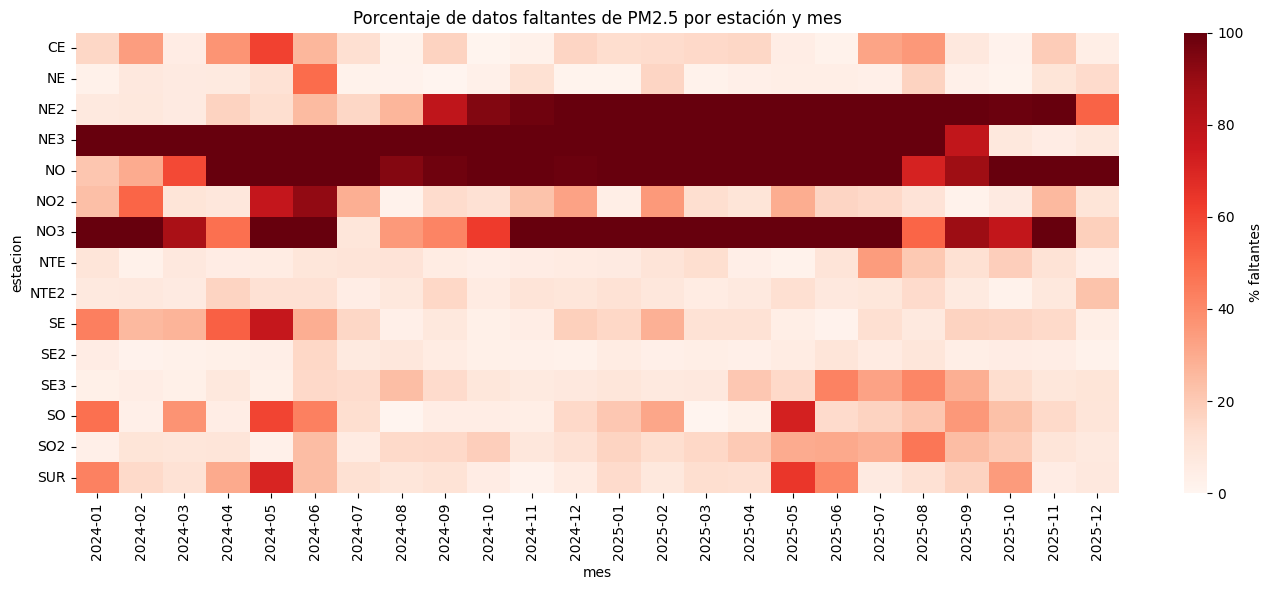

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
sns.heatmap(tabla, cmap="Reds", vmin=0, vmax=100, cbar_kws={"label": "% faltantes"})
plt.title("Porcentaje de datos faltantes de PM2.5 por estación y mes")
plt.tight_layout()
plt.show()

In [10]:
df = df[df["date"].dt.year <= 2025]
print(df.shape)
print(df.isna().mean().mul(100).round(1).sort_values(ascending=False))

df["mes"] = df["date"].dt.to_period("M")
tabla = df.groupby(["estacion", "mes"])["PM2.5"].apply(lambda x: x.isna().mean() * 100).unstack()
validos = tabla <= 25
print(validos.sum(axis=1).sort_values())

(263119, 18)
PM2.5       32.5
RH          14.6
CO          11.1
NO          10.2
TOUT        10.1
NO2          9.2
NOX          9.1
SO2          8.8
O3           5.7
SR           5.1
PM10         4.3
PRS          4.2
RAINF        3.2
WSR          2.9
WDR          2.7
date         0.0
estacion     0.0
mes          0.0
dtype: float64
estacion
NO       1
NO3      2
NE3      3
NE2      6
NO2     16
SE      17
SO      17
CE      18
SUR     18
SE3     20
SO2     20
NE      23
NTE     23
NTE2    24
SE2     24
dtype: int64


In [12]:
# Limpieza y agregación mensual de datos SIMA 2024-2025
# Correr en Colab o Jupyter con los archivos de Excel en la misma carpeta.

import pandas as pd
import numpy as np

ARCHIVOS = ["BD 2024.xlsx", "BD 2025.xlsx"]

CONTAMINANTES = ["PM10", "PM2.5", "NO", "NO2", "NOX", "O3", "CO", "SO2"]
METEO = ["TOUT", "RH", "PRS", "RAINF", "SR", "WSR", "WDR"]
VARIABLES = CONTAMINANTES + METEO

registro = []  # conteo de datos válidos por variable después de cada paso


def conteo(df, paso):
    r = df[VARIABLES].notna().sum()
    r.name = paso
    registro.append(r)


partes = []
for a in ARCHIVOS:
    hojas = pd.read_excel(a, sheet_name=None)
    for estacion, d in hojas.items():
        d = d.rename(columns={"Fecha y hora": "date"})
        d["estacion"] = estacion
        partes.append(d)

df = pd.concat(partes, ignore_index=True)
df["date"] = pd.to_datetime(df["date"])
df = df[df["date"].dt.year <= 2025]

# Texto o símbolos dentro de columnas numéricas se convierten a faltante
for v in VARIABLES:
    df[v] = pd.to_numeric(df[v], errors="coerce")

print("Dimensión inicial:", df.shape)
conteo(df, "0_inicial")


n0 = len(df)
dup_exactos = df.duplicated().sum()
df = df.drop_duplicates()

dup_clave = df.duplicated(subset=["estacion", "date"], keep=False).sum()
df = df.drop_duplicates(subset=["estacion", "date"], keep="first")

print(f"Duplicados exactos eliminados: {dup_exactos}")
print(f"Registros con misma estación y fecha pero valores distintos: {dup_clave}")
print(f"Registros eliminados en total: {n0 - len(df)}")
conteo(df, "1_duplicados")


CENTINELAS = [-9999, -999, -99, 9999]
df[VARIABLES] = df[VARIABLES].replace(CENTINELAS, np.nan)

# 999 exacto en partículas es el tope del equipo o un código, no una medición
for v in ["PM10", "PM2.5"]:
    print(f"{v}: {(df[v] == 999).sum()} valores iguales a 999")
    df.loc[df[v] == 999, v] = np.nan
conteo(df, "2_centinelas")

print(df[VARIABLES].describe().T[["min", "max"]].round(2))

RANGOS = {
    "PM10": (0, 1000),    # µg/m3
    "PM2.5": (0, 1000),   # µg/m3
    "NO": (0, 1000),      # ppb
    "NO2": (0, 1000),     # ppb
    "NOX": (0, 2000),     # ppb
    "O3": (0, 300),       # ppb
    "CO": (0, 50),        # ppm
    "SO2": (0, 500),      # ppb
    "TOUT": (-10, 50),    # °C
    "RH": (0, 100),       # %
    "PRS": (650, 800),    # mmHg
    "RAINF": (0, 150),    # mm/h
    "SR": (0, 1.5),       # kW/m2
    "WSR": (0, 150),      # km/h
    "WDR": (0, 360),      # grados
}

for v, (lo, hi) in RANGOS.items():
    fuera = (df[v] < lo) | (df[v] > hi)
    print(f"{v}: {fuera.sum()} valores fuera de rango")
    df.loc[fuera, v] = np.nan
conteo(df, "3_rangos")


RACHA_HORAS = 6
VARS_RACHA = ["PM10", "PM2.5", "NO", "NO2", "NOX", "O3", "TOUT", "RH"]

# Valores que sí pueden repetirse varias horas sin que sea falla:
# el límite de detección de los gases (0.5 ppb) en horas limpias
# y la humedad al 100% durante lluvia o neblina.
EXENTOS = {"NO": 0.5, "NO2": 0.5, "NOX": 0.5, "O3": 0.5, "RH": 100}

df = df.sort_values(["estacion", "date"]).reset_index(drop=True)
for v in VARS_RACHA:
    s = df[v]
    cambio = (s != s.shift()) | (df["estacion"] != df["estacion"].shift())
    grupo = cambio.cumsum()
    largo = s.groupby(grupo).transform("size")
    racha = (largo >= RACHA_HORAS) & s.notna()
    if v in EXENTOS:
        limite = EXENTOS[v]
        racha &= (s > limite) if v != "RH" else (s < limite)
    print(f"{v}: {racha.sum()} valores en rachas constantes")
    df.loc[racha, v] = np.nan
conteo(df, "4_rachas")


incongruente = df["PM2.5"] > df["PM10"]
print(f"Horas con PM2.5 > PM10: {incongruente.sum()}")
df.loc[incongruente, ["PM2.5", "PM10"]] = np.nan
conteo(df, "5_pm25_mayor_pm10")


df.to_csv("base_horaria_limpia_2024_2025.csv", index=False)
print("Base horaria limpia:", df.shape)

resumen = pd.concat(registro, axis=1)
resumen["eliminados_total"] = resumen["0_inicial"] - resumen.iloc[:, -1]
resumen["pct_eliminado"] = (resumen["eliminados_total"] / resumen["0_inicial"] * 100).round(2)
resumen.to_csv("resumen_limpieza.csv")
print(resumen)

# Tabla de antes y después lista para LaTeX
tabla_tex = resumen[["0_inicial", "1_duplicados", "2_centinelas", "3_rangos",
                     "4_rachas", "5_pm25_mayor_pm10", "pct_eliminado"]].copy()
tabla_tex.columns = ["Inicial", "Duplicados", "Centinelas", "Rangos",
                     "Rachas", "PM2.5>PM10", "\\% eliminado"]
with open("resumen_limpieza.tex", "w") as f:
    f.write(tabla_tex.to_latex(
        caption="Datos válidos por variable después de cada regla de limpieza.",
        label="tab:limpieza",
        escape=False,
        float_format="%.2f",
    ))


#  Agregación mensual con criterio de 75%
df["anio"] = df["date"].dt.year
df["mes"] = df["date"].dt.month
g = df.groupby(["estacion", "anio", "mes"])

promedios = g[VARIABLES].mean()
validas = g[VARIABLES].count()

# Horas esperadas en cada mes, para no ignorar las filas que faltan
dias = [pd.Period(year=a, month=m, freq="M").days_in_month for _, a, m in promedios.index]
esperadas = np.array(dias) * 24
cobertura = validas.div(esperadas, axis=0)

mensual = promedios.where(cobertura >= 0.75)

# Lluvia como total mensual en mm
mensual["RAINF"] = g["RAINF"].sum(min_count=1).where(cobertura["RAINF"] >= 0.75)

# Dirección del viento con promedio circular
rad = np.deg2rad(df["WDR"])
seno = rad.apply(np.sin).groupby([df["estacion"], df["anio"], df["mes"]]).mean()
coseno = rad.apply(np.cos).groupby([df["estacion"], df["anio"], df["mes"]]).mean()
mensual["WDR"] = (np.rad2deg(np.arctan2(seno, coseno)) % 360).where(cobertura["WDR"] >= 0.75)

# Cobertura de los contaminantes principales, como referencia
for v in ["PM10", "PM2.5", "NO2"]:
    mensual[f"cobertura_{v}"] = cobertura[v].round(3)

mensual = mensual.reset_index()


MIN_MESES = 12
meses_pm25 = mensual.groupby("estacion")["PM2.5"].count()
excluidas = meses_pm25[meses_pm25 < MIN_MESES].index.tolist()
mensual.loc[mensual["estacion"].isin(excluidas), "PM2.5"] = np.nan
print("Estaciones excluidas para PM2.5:", excluidas)

mensual["fecha"] = pd.to_datetime(dict(year=mensual["anio"], month=mensual["mes"], day=1))
mensual["temporada"] = np.where(mensual["mes"].between(5, 10), "humeda", "seca")

mensual.to_csv("base_mensual_2024_2025.csv", index=False)

print("\nBase mensual:", mensual.shape)
for v in ["PM10", "PM2.5", "NO2"]:
    n = mensual[v].notna().sum()
    e = mensual.loc[mensual[v].notna(), "estacion"].nunique()
    print(f"{v}: {n} observaciones válidas en {e} estaciones")

Dimensión inicial: (263119, 17)
Duplicados exactos eliminados: 0
Registros con misma estación y fecha pero valores distintos: 0
Registros eliminados en total: 0
PM10: 1 valores iguales a 999
PM2.5: 1 valores iguales a 999
        min    max
PM10   1.00  998.0
PM2.5  0.00  729.0
NO     0.50  495.8
NO2    0.00  165.1
NOX    0.50  702.2
O3     0.50  184.0
CO     0.00   37.0
SO2    0.50  404.7
TOUT  -8.75  785.0
RH     0.00  725.0
PRS    0.00  750.0
RAINF  0.00  360.0
SR    -0.01  604.0
WSR    0.10  337.0
WDR    1.00  360.0
PM10: 0 valores fuera de rango
PM2.5: 0 valores fuera de rango
NO: 0 valores fuera de rango
NO2: 0 valores fuera de rango
NOX: 0 valores fuera de rango
O3: 0 valores fuera de rango
CO: 0 valores fuera de rango
SO2: 0 valores fuera de rango
TOUT: 2 valores fuera de rango
RH: 34 valores fuera de rango
PRS: 2 valores fuera de rango
RAINF: 20 valores fuera de rango
SR: 233 valores fuera de rango
WSR: 1 valores fuera de rango
WDR: 0 valores fuera de rango
PM10: 68 valores en